# Early stopping

-> A technique to overcome overfitting in machine learning and neural networks.

In [2]:
# importing necessary libraries 
import tensorflow as tf 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import warnings 
from mlxtend.plotting import plot_decision_regions 
from matplotlib.colors import ListedColormap 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping 
from sklearn.model_selection import train_test_split 
from sklearn.datasets import make_circles 
import seaborn as sb

In [3]:
# creating the dataset 
X,Y = make_circles(n_samples=100,noise=0.1,random_state=1) 

<Axes: >

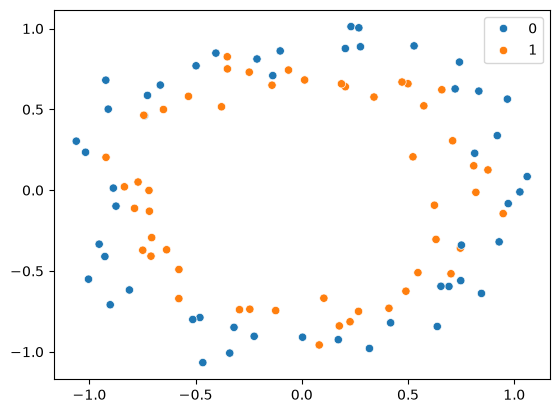

In [4]:
# visualizing the dataset 
sb.scatterplot(x=X[:,0],y=X[:,1],hue=Y)

In [5]:
# seperating the data into training and testing part 
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=3)

In [6]:
model = Sequential() 

model.add(Dense(128,input_dim=2,activation='relu')) 
model.add(Dense(1,activation='sigmoid'))

C:\Users\Sakriya Pyakurel\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
# model compiliation and training 
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
history=model.fit(X_train,Y_train,validation_data=(X_test,Y_test),epochs=3500,verbose=0)

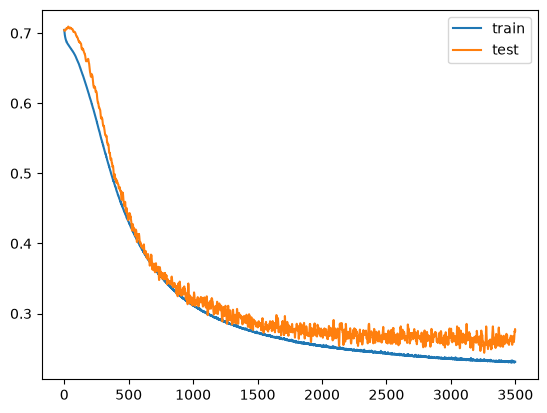

In [8]:
# plotting loss of the model 
plt.plot(history.history['loss'],label='train') 
plt.plot(history.history['val_loss'],label='test')
plt.legend() 
plt.show()

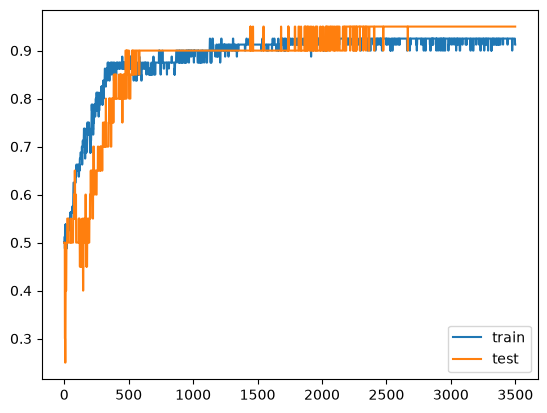

In [22]:
# plotting accuracy of the model 
plt.plot(history.history['accuracy'],label='train') 
plt.plot(history.history['val_accuracy'],label='test')
plt.legend() 
plt.show()

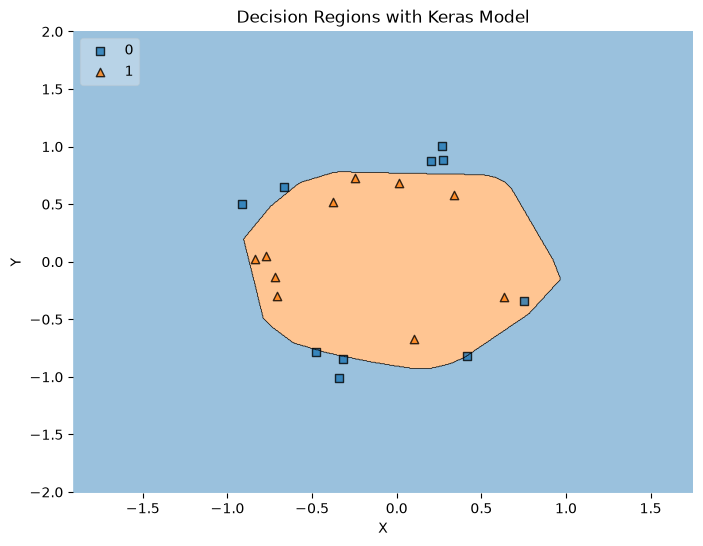

In [13]:
# Creating a wrapper class to make the Keras model compatible with mlxtend
class KerasClassifierWrapper:
    def __init__(self, model):
        self.model = model
    
    def predict(self, X):
        # Predicting probabilities, threshold at 0.5, and cast to integers
        preds = self.model.predict(X, verbose=0)
        return (preds > 0.5).astype(int).ravel()

# Wrapping trained keras model
wrapped_model = KerasClassifierWrapper(model)

# Ensuring test features and labels are clean numpy arrays
X_test_arr = np.array(X_test)
y_test_arr = np.array(Y_test).ravel().astype(int)

# Plotting decision boundary using the wrapper
plt.figure(figsize=(8, 6))
plot_decision_regions(X_test_arr, y_test_arr, clf=wrapped_model, legend=2)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Decision Regions with Keras Model')
plt.show()

In [26]:
# implementing early stopping 
callback = EarlyStopping(
    monitor='val_loss',
    min_delta=0.00004,
    patience=50,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [27]:
es_history = model.fit(X_train,Y_train,verbose=1,epochs=3500,callbacks=callback,validation_data=(X_test,Y_test))

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9125 - loss: 0.2298 - val_accuracy: 0.9500 - val_loss: 0.2463
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9125 - loss: 0.2293 - val_accuracy: 0.9500 - val_loss: 0.2475
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9125 - loss: 0.2293 - val_accuracy: 0.9500 - val_loss: 0.2505
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9250 - loss: 0.2294 - val_accuracy: 0.9500 - val_loss: 0.2558
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9250 - loss: 0.2289 - val_accuracy: 0.9500 - val_loss: 0.2585
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9250 - loss: 0.2299 - val_accuracy: 0.9500 - val_loss: 0.2610
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9250 - loss: 0.2291 - val_accuracy: 0.9500 - val_loss: 0.2683
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.9250 - loss: 0.2296 - val_accuracy: 0.9500 - v

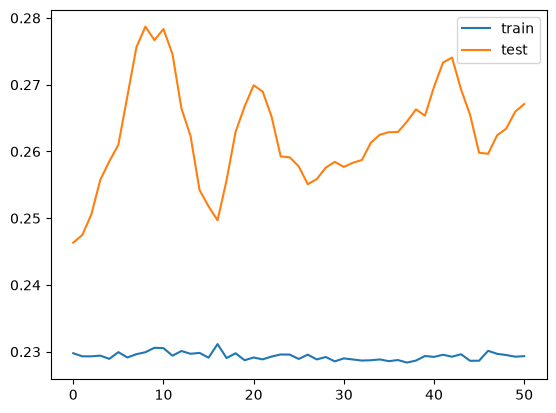

In [28]:
# plotting loss of the model with early stopping
plt.plot(es_history.history['loss'],label='train') 
plt.plot(es_history.history['val_loss'],label='test')
plt.legend() 
plt.show()

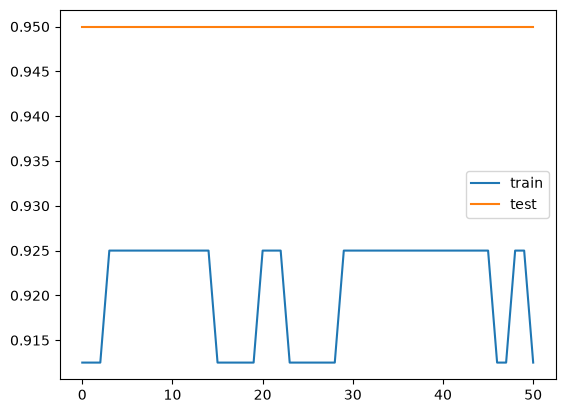

In [29]:
# plotting accuracy of the model with early stopping
plt.plot(es_history.history['accuracy'],label='train') 
plt.plot(es_history.history['val_accuracy'],label='test')
plt.legend() 
plt.show()

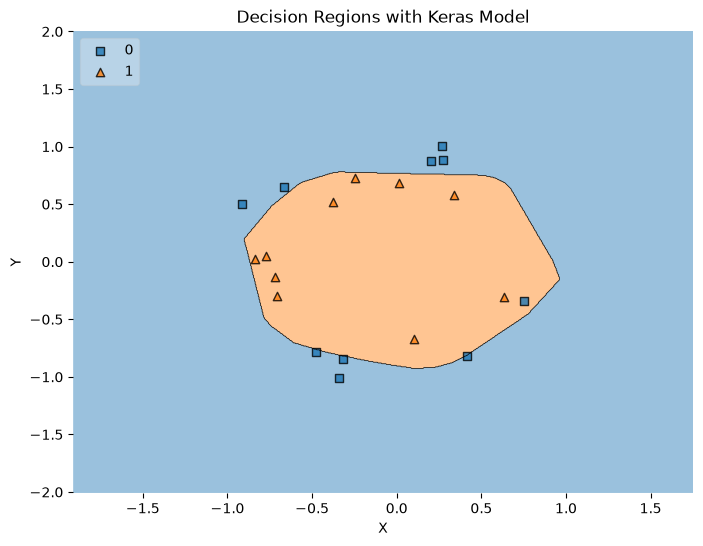

In [30]:
wrapped_model = KerasClassifierWrapper(model)
plt.figure(figsize=(8, 6))
plot_decision_regions(X_test_arr, y_test_arr, clf=wrapped_model, legend=2)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Decision Regions with Keras Model')
plt.show()